<a href="https://colab.research.google.com/github/mhmdNasil/ML/blob/main/ML_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **POLYNOMIAL REGRESSION**

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0  3504.0          12.0   
1  15.0          8         350.0       165.0  3693.0          11.5   
2  18.0          8         318.0       150.0  3436.0          11.0   
3  16.0          8         304.0       150.0  3433.0          12.0   
4  17.0          8         302.0       140.0  3449.0          10.5   

   model_year  origin                       name  
0          70       1  chevrolet chevelle malibu  
1          70       1          buick skylark 320  
2          70       1         plymouth satellite  
3          70       1              amc rebel sst  
4          70       1                ford torino  
First 5 rows:
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0  3504.0          12.0   
1  15.0          8         350.0       165.0  3693.0          11.5   
2  18.0          8         318.0       150.0  343

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


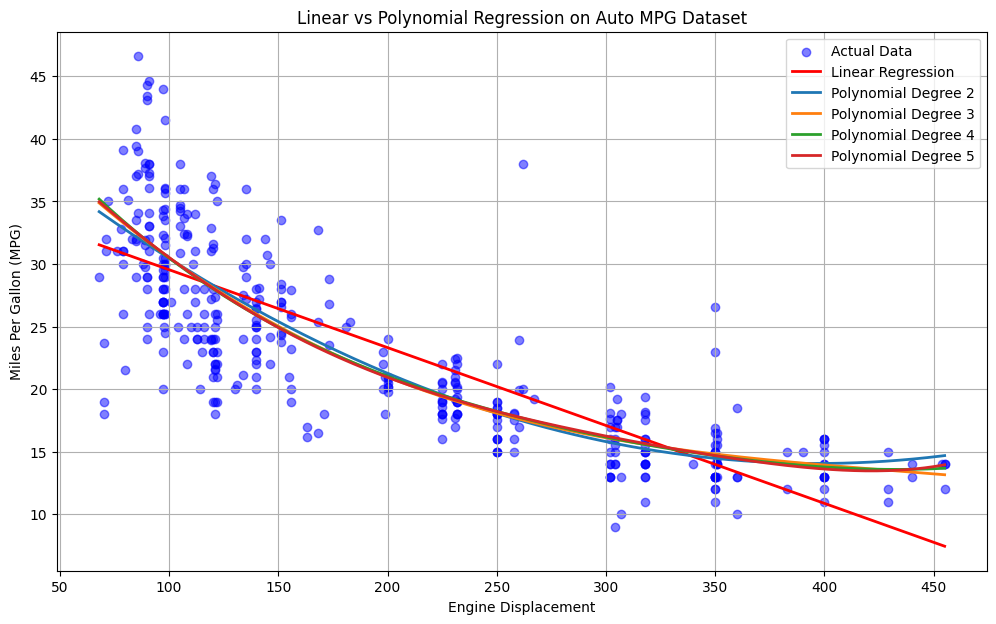

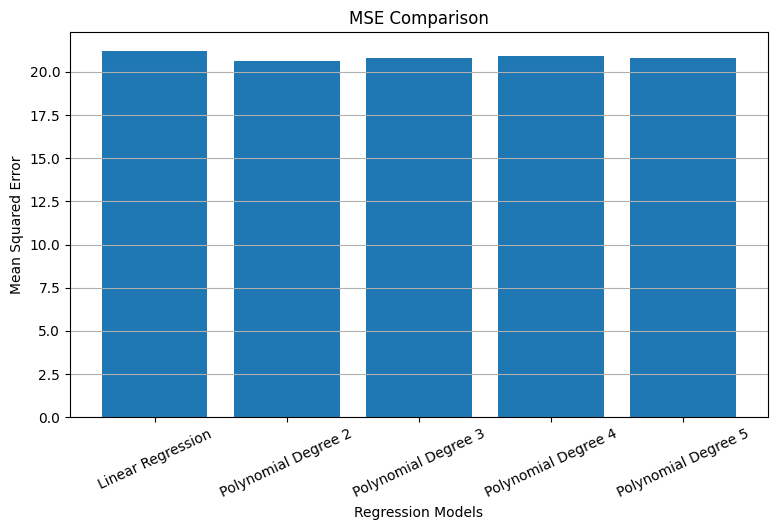

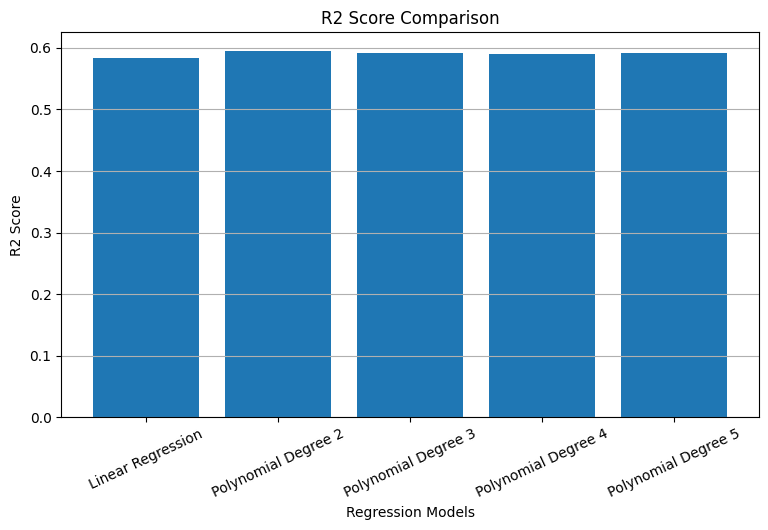

In [1]:

# POLYNOMIAL REGRESSION ON AUTO MPG DATASET

# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score


# 2. Load the dataset
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

columns = [
    "mpg", "cylinders", "displacement",
    "horsepower", "weight", "acceleration",
    "model_year", "origin", "name"
]

df = pd.read_csv(
    url,
    sep=r"\s+",
    names=columns,
    na_values="?"
)

df.dropna(inplace=True)

print(df.head())

print("First 5 rows:")
print(df.head())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())


# 3. Data preprocessing

# Convert horsepower into numeric format if present
if "horsepower" in df.columns:
    df["horsepower"] = pd.to_numeric(
        df["horsepower"], errors="coerce"
    )

# Remove missing values
df.dropna(inplace=True)

# Remove unnecessary name column
if "name" in df.columns:
    df.drop("name", axis=1, inplace=True)

print("\nDataset after preprocessing:")
print(df.shape)


# 4. Select independent and dependent variables

X = df[["displacement"]]
y = df["mpg"]

print("\nIndependent variable: Displacement")
print("Dependent variable: MPG")


# 5. Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# 6. Linear Regression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

print("\n========== LINEAR REGRESSION ==========")
print("MSE:", linear_mse)
print("R2 Score:", linear_r2)


# 7. Polynomial Regression with different degrees

degrees = [2, 3, 4, 5]

results = []

models = {}

for degree in degrees:

    poly_model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    # Train the model
    poly_model.fit(X_train, y_train)

    # Predict test data
    y_pred = poly_model.predict(X_test)

    # Calculate evaluation metrics
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Store the trained model
    models[degree] = poly_model

    # Store results
    results.append({
        "Model": "Polynomial Degree " + str(degree),
        "MSE": mse,
        "R2 Score": r2
    })

    print("\n========== POLYNOMIAL DEGREE", degree, "==========")
    print("MSE:", mse)
    print("R2 Score:", r2)


# 8. Compare all models

comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MSE": linear_mse,
        "R2 Score": linear_r2
    }
] + results)

print("\n========== MODEL COMPARISON ==========")
print(comparison.to_string(index=False))


# 9. Find the best model based on test MSE

best_index = comparison["MSE"].idxmin()
best_model = comparison.loc[best_index]

print("\n========== BEST MODEL ==========")
print("Best Model:", best_model["Model"])
print("Best MSE:", best_model["MSE"])
print("Best R2 Score:", best_model["R2 Score"])


# 10. Visualize actual data and regression curves

plt.figure(figsize=(12, 7))

# Actual data points
plt.scatter(
    X["displacement"],
    y,
    color="blue",
    alpha=0.5,
    label="Actual Data"
)

# Smooth values for plotting
X_plot = np.linspace(
    X["displacement"].min(),
    X["displacement"].max(),
    300
).reshape(-1, 1)

# Linear regression line
y_linear = linear_model.predict(X_plot)

plt.plot(
    X_plot,
    y_linear,
    color="red",
    linewidth=2,
    label="Linear Regression"
)

# Polynomial regression curves
for degree in degrees:

    y_poly = models[degree].predict(X_plot)

    plt.plot(
        X_plot,
        y_poly,
        linewidth=2,
        label="Polynomial Degree " + str(degree)
    )

plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")

plt.title("Linear vs Polynomial Regression on Auto MPG Dataset")

plt.legend()
plt.grid(True)
plt.show()


# 11. Plot MSE comparison

plt.figure(figsize=(9, 5))

plt.bar(comparison["Model"], comparison["MSE"])

plt.xlabel("Regression Models")
plt.ylabel("Mean Squared Error")
plt.title("MSE Comparison")

plt.xticks(rotation=25)
plt.grid(axis="y")
plt.show()


# 12. Plot R2 comparison

plt.figure(figsize=(9, 5))

plt.bar(comparison["Model"], comparison["R2 Score"])

plt.xlabel("Regression Models")
plt.ylabel("R2 Score")
plt.title("R2 Score Comparison")

plt.xticks(rotation=25)
plt.grid(axis="y")
plt.show()


## **LOGISTIC REGRESSION**

Dataset shape: (768, 9)

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Column names:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressu

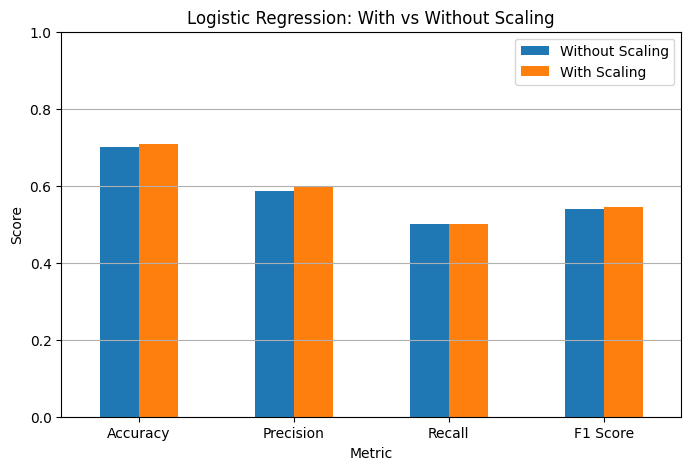

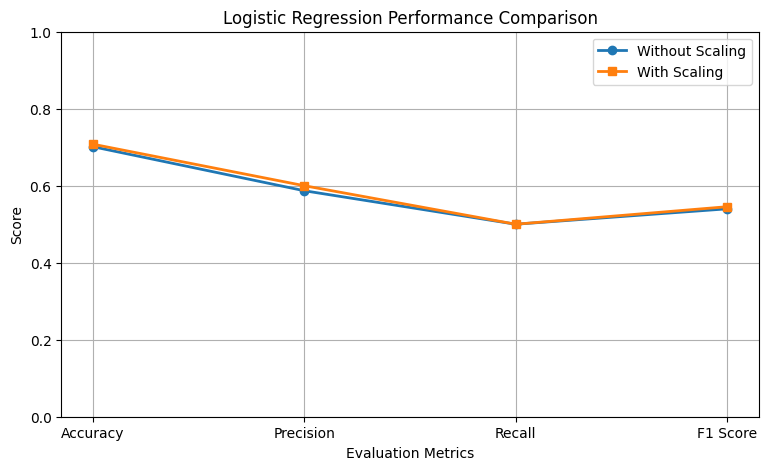

In [7]:
# ============================================================
# PIMA INDIANS DIABETES - LOGISTIC REGRESSION
# With and Without Feature Scaling
# ============================================================

# Import libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. LOAD DATASET
# ============================================================

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nColumn names:")
print(df.columns)

# ============================================================
# 2. CHECK MISSING VALUES
# ============================================================

print("\nMissing values:")
print(df.isnull().sum())

# ============================================================
# 3. PREPROCESSING
# ============================================================

# Separate input features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("\nFeatures:")
print(X.columns)

print("\nTarget:")
print(y.name)

# In this dataset, some medical measurements use 0
# where 0 is not a realistic physiological value.
# Replace those zeros with NaN and fill with median.

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X[zero_columns] = X[zero_columns].replace(0, np.nan)

# Replace missing values with median
X[zero_columns] = X[zero_columns].fillna(X[zero_columns].median())

print("\nMissing values after preprocessing:")
print(X.isnull().sum())

# ============================================================
# 4. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Testing data :", X_test.shape)

# ============================================================
# 5. LOGISTIC REGRESSION WITHOUT SCALING
# ============================================================

model_unscaled = LogisticRegression(max_iter=1000)

model_unscaled.fit(X_train, y_train)

# Predictions
y_pred_unscaled = model_unscaled.predict(X_test)

# Metrics
accuracy_unscaled = accuracy_score(y_test, y_pred_unscaled)
precision_unscaled = precision_score(y_test, y_pred_unscaled)
recall_unscaled = recall_score(y_test, y_pred_unscaled)
f1_unscaled = f1_score(y_test, y_pred_unscaled)

print("\n========================================")
print("WITHOUT FEATURE SCALING")
print("========================================")

print("Accuracy :", accuracy_unscaled)
print("Precision:", precision_unscaled)
print("Recall   :", recall_unscaled)
print("F1 Score :", f1_unscaled)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_unscaled))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_unscaled))

# ============================================================
# 6. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

# IMPORTANT:
# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Only transform test data
X_test_scaled = scaler.transform(X_test)

# ============================================================
# 7. LOGISTIC REGRESSION WITH SCALING
# ============================================================

model_scaled = LogisticRegression(max_iter=1000)

model_scaled.fit(X_train_scaled, y_train)

# Predictions
y_pred_scaled = model_scaled.predict(X_test_scaled)

# Metrics
accuracy_scaled = accuracy_score(y_test, y_pred_scaled)
precision_scaled = precision_score(y_test, y_pred_scaled)
recall_scaled = recall_score(y_test, y_pred_scaled)
f1_scaled = f1_score(y_test, y_pred_scaled)

print("\n========================================")
print("WITH FEATURE SCALING")
print("========================================")

print("Accuracy :", accuracy_scaled)
print("Precision:", precision_scaled)
print("Recall   :", recall_scaled)
print("F1 Score :", f1_scaled)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_scaled))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_scaled))

# ============================================================
# 8. COMPARE BOTH MODELS
# ============================================================

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Without Scaling": [
        accuracy_unscaled,
        precision_unscaled,
        recall_unscaled,
        f1_unscaled
    ],
    "With Scaling": [
        accuracy_scaled,
        precision_scaled,
        recall_scaled,
        f1_scaled
    ]
})

print("\n========================================")
print("MODEL COMPARISON")
print("========================================")

print(results)

# ============================================================
# 9. VISUALIZE COMPARISON
# ============================================================

results.set_index("Metric").plot(
    kind="bar",
    figsize=(8, 5)
)

import matplotlib.pyplot as plt

plt.title("Logistic Regression: With vs Without Scaling")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.show()

# 9. VISUALIZE COMPARISON USING LINE GRAPH

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

without_scaling = [
    accuracy_unscaled,
    precision_unscaled,
    recall_unscaled,
    f1_unscaled
]

with_scaling = [
    accuracy_scaled,
    precision_scaled,
    recall_scaled,
    f1_scaled
]

plt.figure(figsize=(9, 5))

plt.plot(
    metrics,
    without_scaling,
    marker='o',
    linewidth=2,
    label='Without Scaling'
)

plt.plot(
    metrics,
    with_scaling,
    marker='s',
    linewidth=2,
    label='With Scaling'
)

plt.title("Logistic Regression Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)

plt.show()


# **KNN**

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


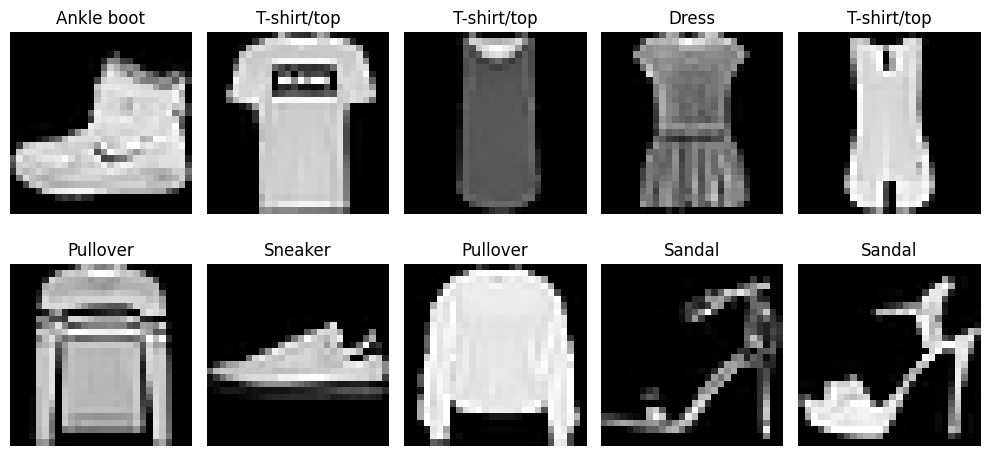

After preprocessing:
Training data: (60000, 784)
Testing data: (10000, 784)

Samples used for KNN:
Training: (10000, 784)
Testing : (2000, 784)

K = 1
Accuracy : 0.8075
Precision: 0.8157
Recall   : 0.8075
F1 Score : 0.8096
Training Time  : 0.0083 seconds
Prediction Time: 1.3532 seconds

K = 3
Accuracy : 0.8195
Precision: 0.8266
Recall   : 0.8195
F1 Score : 0.8202
Training Time  : 0.0049 seconds
Prediction Time: 1.2239 seconds

K = 5
Accuracy : 0.8225
Precision: 0.8279
Recall   : 0.8225
F1 Score : 0.8229
Training Time  : 0.005 seconds
Prediction Time: 1.2074 seconds

K = 7
Accuracy : 0.826
Precision: 0.8319
Recall   : 0.826
F1 Score : 0.8267
Training Time  : 0.005 seconds
Prediction Time: 1.2132 seconds

K = 9
Accuracy : 0.822
Precision: 0.8285
Recall   : 0.822
F1 Score : 0.8227
Training Time  : 0.005 seconds
Prediction Time: 1.2238 seconds

FINAL PERFORMANCE COMPARISON
 K  Accuracy  Precision  Recall  F1 Score  Training Time  Prediction Time
 1    0.8075   0.815700  0.8075  0.809632   

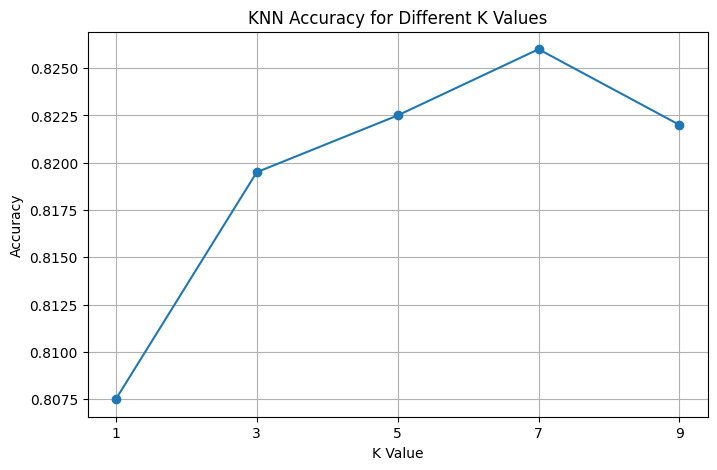

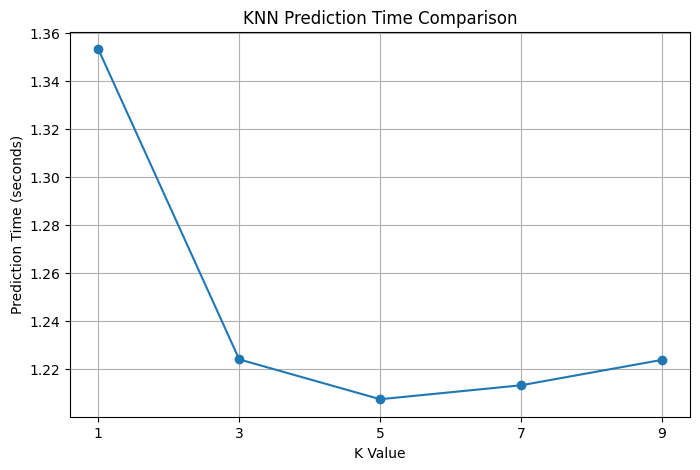


BEST MODEL
Best K: 7
Best Accuracy: 0.826


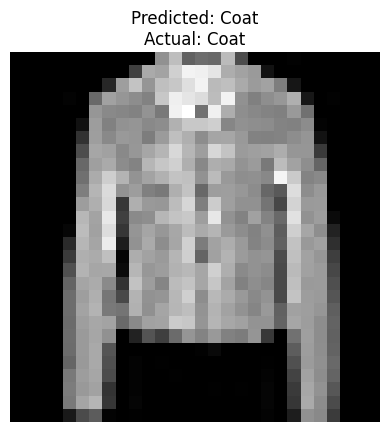

In [12]:
# ============================================================
# KNN IMAGE CLASSIFICATION USING FASHION MNIST ONLINE DATASET
# ============================================================

# 1. Import required libraries

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from tensorflow.keras.datasets import fashion_mnist

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

# ============================================================
# 2. LOAD FASHION MNIST DATASET FROM INTERNET
# ============================================================

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

# ============================================================
# 3. DISPLAY CLASS NAMES
# ============================================================

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# ============================================================
# 4. DISPLAY SAMPLE IMAGES
# ============================================================

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# 5. PREPROCESS THE DATASET
# ============================================================

# Normalize pixel values from 0-255 to 0-1

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Convert 28x28 images into 784-dimensional vectors

X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

print("After preprocessing:")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# ============================================================
# 6. USE A SUBSET TO REDUCE COMPUTATION TIME
# ============================================================

# Full dataset contains 60,000 training and 10,000 testing images.
# KNN is computationally expensive, so use a subset.

X_train = X_train[:10000]
y_train = y_train[:10000]

X_test = X_test[:2000]
y_test = y_test[:2000]

print("\nSamples used for KNN:")
print("Training:", X_train.shape)
print("Testing :", X_test.shape)

# ============================================================
# 7. IMPLEMENT KNN FOR DIFFERENT K VALUES
# ============================================================

k_values = [1, 3, 5, 7, 9]

results = []

for k in k_values:

    print("\n================================")
    print("K =", k)
    print("================================")

    # Create KNN classifier

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean",
        n_jobs=-1
    )

    # Train the model

    start_train = time.time()

    knn.fit(X_train, y_train)

    training_time = time.time() - start_train

    # Predict test labels

    start_test = time.time()

    y_pred = knn.predict(X_test)

    prediction_time = time.time() - start_test

    # Evaluate model

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("Training Time  :", round(training_time, 4), "seconds")
    print("Prediction Time:", round(prediction_time, 4), "seconds")

    results.append([
        k,
        accuracy,
        precision,
        recall,
        f1,
        training_time,
        prediction_time
    ])

# ============================================================
# 8. DISPLAY COMPARISON TABLE
# ============================================================

results_df = pd.DataFrame(
    results,
    columns=[
        "K",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Training Time",
        "Prediction Time"
    ]
)

print("\nFINAL PERFORMANCE COMPARISON")

print(results_df.to_string(index=False))

# ============================================================
# 9. PLOT ACCURACY VS K
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Accuracy"],
    marker="o"
)

plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.xticks(k_values)
plt.grid(True)

plt.show()

# ============================================================
# 10. PLOT PREDICTION TIME VS K
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Prediction Time"],
    marker="o"
)

plt.xlabel("K Value")
plt.ylabel("Prediction Time (seconds)")
plt.title("KNN Prediction Time Comparison")
plt.xticks(k_values)
plt.grid(True)

plt.show()

# ============================================================
# 11. FIND BEST K VALUE
# ============================================================

best_index = results_df["Accuracy"].idxmax()

best_k = results_df.loc[best_index, "K"]
best_accuracy = results_df.loc[best_index, "Accuracy"]

print("\nBEST MODEL")
print("Best K:", best_k)
print("Best Accuracy:", round(best_accuracy, 4))

# ============================================================
# 12. TEST PREDICTION ON ONE IMAGE
# ============================================================

sample_index = 10

prediction = knn.predict([X_test[sample_index]])

plt.imshow(
    X_test[sample_index].reshape(28, 28),
    cmap="gray"
)

plt.title(
    "Predicted: " + class_names[prediction[0]]
    + "\nActual: " + class_names[y_test[sample_index]]
)

plt.axis("off")
plt.show()

## **ID3 DECISION TREE**

Original dataset shape: (541909, 8)

First 5 rows:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  

After preprocessing: (397884, 9)

Customer-level dataset:
   CustomerID  Recency  TotalTransactions  TotalQuantity  TotalSpent
0     12346.0      326            

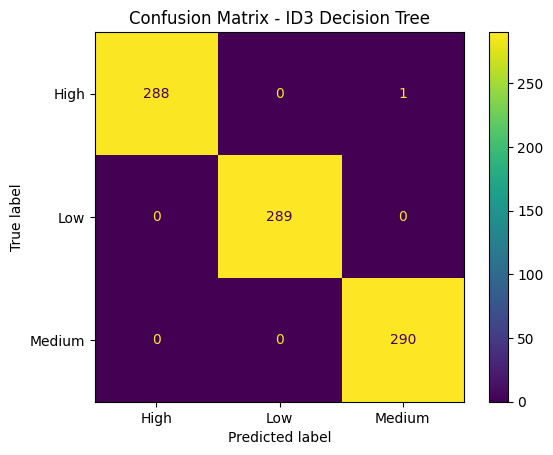

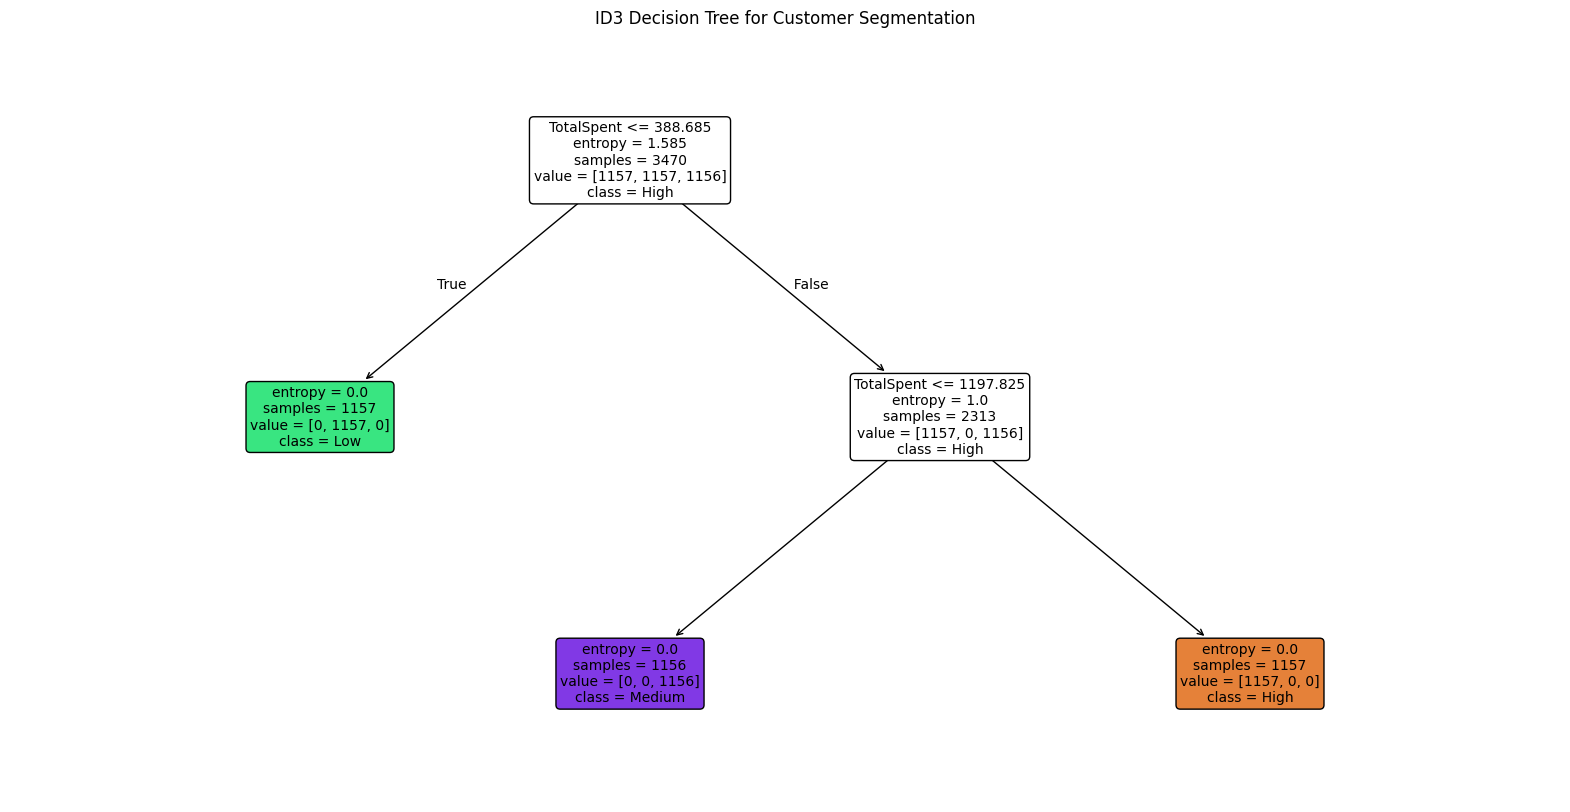


========== FEATURE IMPORTANCE ==========
             Feature  Importance
3         TotalSpent         1.0
0            Recency         0.0
1  TotalTransactions         0.0
2      TotalQuantity         0.0


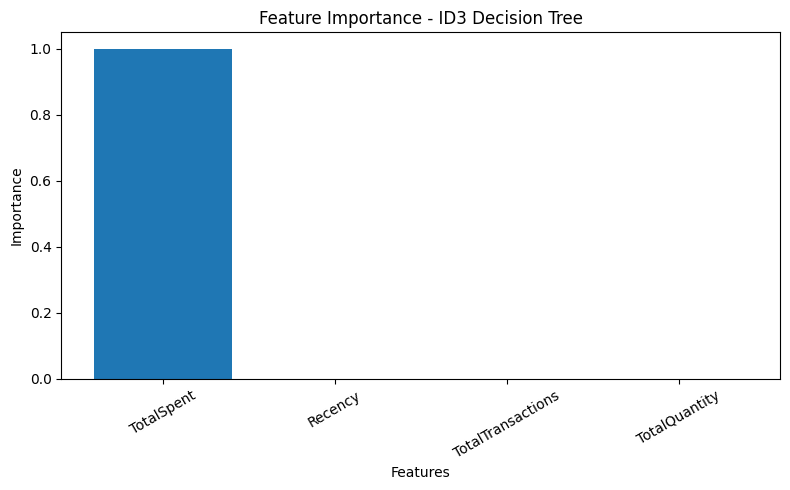

In [2]:

# ============================================================
# DECISION TREE CLASSIFIER USING ID3
# ONLINE RETAIL DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder

# ============================================================
# 1. LOAD DATASET
# ============================================================

file_path = "https://github.com/dbdmg/data-science-lab/raw/master/datasets/online_retail.csv"

df = pd.read_csv(file_path)

print("Original dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# ============================================================
# 2. PREPROCESSING
# ============================================================

# Remove rows without CustomerID
df = df.dropna(subset=["CustomerID"])

# Remove cancelled invoices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Keep only positive quantity and price
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Calculate total price for each transaction
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("\nAfter preprocessing:", df.shape)

# ============================================================
# 3. CREATE CUSTOMER-LEVEL FEATURES
# ============================================================

# Reference date = day after the last transaction
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_df = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),

    TotalTransactions=("InvoiceNo", "nunique"),

    TotalQuantity=("Quantity", "sum"),

    TotalSpent=("TotalPrice", "sum")
).reset_index()

print("\nCustomer-level dataset:")
print(customer_df.head())

print("\nCustomer dataset shape:", customer_df.shape)

# ============================================================
# 4. CREATE TARGET VARIABLE
# ============================================================

# Divide customers into 3 equal-sized groups
customer_df["ValueSegment"] = pd.qcut(
    customer_df["TotalSpent"],
    q=3,
    labels=["Low", "Medium", "High"]
)

print("\nSegment distribution:")
print(customer_df["ValueSegment"].value_counts())

# ============================================================
# 5. PREPARE X AND Y
# ============================================================

features = [
    "Recency",
    "TotalTransactions",
    "TotalQuantity",
    "TotalSpent"
]

X = customer_df[features]
y = customer_df["ValueSegment"]

# Encode target
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nTarget classes:")
print(label_encoder.classes_)

# ============================================================
# 6. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# ============================================================
# 7. ID3 DECISION TREE
# ============================================================

# ID3 uses entropy as the splitting criterion
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42,
    max_depth=4
)

model.fit(X_train, y_train)

# ============================================================
# 8. PREDICTION
# ============================================================

y_pred = model.predict(X_test)

# ============================================================
# 9. EVALUATION
# ============================================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("\n========== MODEL PERFORMANCE ==========")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot()
plt.title("Confusion Matrix - ID3 Decision Tree")
plt.show()

# ============================================================
# 11. VISUALIZE DECISION TREE
# ============================================================

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=features,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("ID3 Decision Tree for Customer Segmentation")
plt.show()

# ============================================================
# 12. FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\n========== FEATURE IMPORTANCE ==========")
print(importance)

# ============================================================
# 13. FEATURE IMPORTANCE GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance - ID3 Decision Tree")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# **SVM**

First five rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Accuracy: 1.0

Confusion Matrix:
[[20  0]
 [ 0 10]]

Classification Report:
              precision    recall  f1-score   support

  Non-Setosa       1.00      1.00      1.00        20
      Setosa       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Support Vectors:
[[-0.89592797 -0.43081309]
 [-1.01407232 -0.26056862]
 [-1.13221667 -0.26056862]
 [-0.89592797 -1.05504282]
 [-0.89592797 -1.16853914]
 [-1.25036102 -1.05504282]
 [-0.18706188 -1

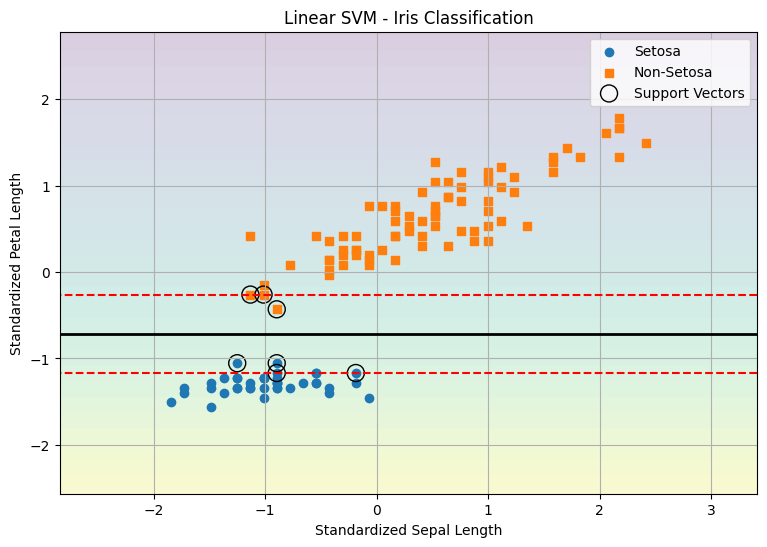

In [13]:

# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 2. Load Iris dataset from an online source
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

print("First five rows:")
print(df.head())

# 3. Separate input features and target
X = df[['sepal_length', 'petal_length']]
y = df['species']

# 4. Convert into binary classification
# Setosa = 1, Other flowers = 0
y = (y == 'setosa').astype(int)

# 5. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Standardize the features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 7. Create Linear SVM model
model = SVC(kernel='linear', C=1.0)

# 8. Train the model
model.fit(X_train, y_train)

# 9. Predict test data
y_pred = model.predict(X_test)

# 10. Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Non-Setosa', 'Setosa']
))

# 11. Display support vectors
print("Support Vectors:")
print(model.support_vectors_)

# 12. Create points for decision boundary visualization
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = model.decision_function(grid).reshape(xx.shape)

# 13. Plot decision boundary and margins
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, levels=30, alpha=0.2)

# Decision boundary: w.x + b = 0
plt.contour(xx, yy, Z, levels=[0], colors='black', linewidths=2)

# Margin lines: w.x + b = -1 and +1
plt.contour(
    xx, yy, Z,
    levels=[-1, 1],
    colors='red',
    linestyles='dashed'
)

# Plot training samples
plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    label='Setosa',
    marker='o'
)

plt.scatter(
    X_train[y_train == 0, 0],
    X_train[y_train == 0, 1],
    label='Non-Setosa',
    marker='s'
)

# Highlight support vectors
plt.scatter(
    model.support_vectors_[:, 0],
    model.support_vectors_[:, 1],
    s=150,
    facecolors='none',
    edgecolors='black',
    label='Support Vectors'
)

plt.xlabel('Standardized Sepal Length')
plt.ylabel('Standardized Petal Length')
plt.title('Linear SVM - Iris Classification')
plt.legend()
plt.grid()
plt.show()


# **MLP**

Dataset Shape: (1599, 12)

First 5 rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1

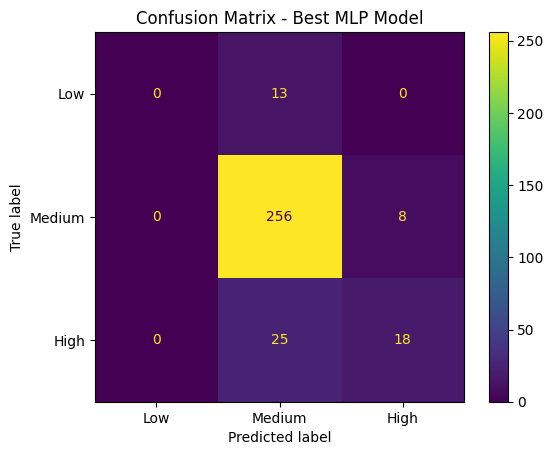

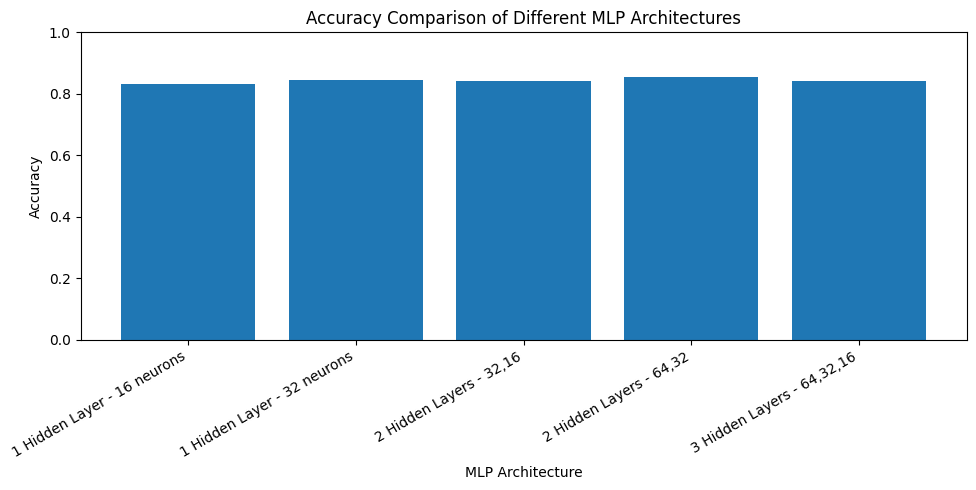

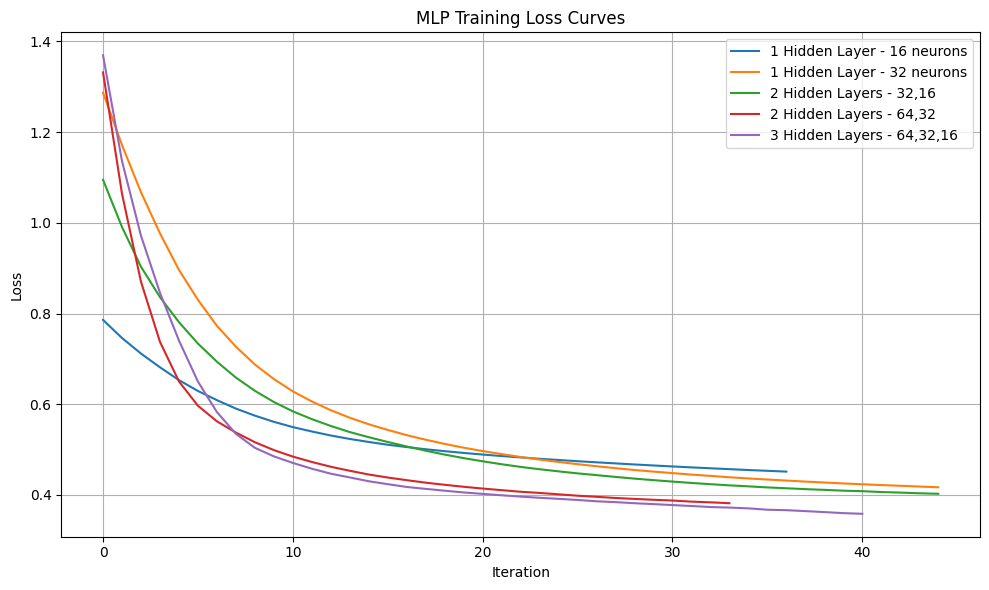

In [1]:
# ============================================================
# MLP CLASSIFIER - WINE QUALITY DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. LOAD DATASET
# ============================================================

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# 2. PREPROCESSING
# ============================================================

# Remove Id column if it exists
if "Id" in df.columns:
    df = df.drop("Id", axis=1)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Remove rows containing missing values
df = df.dropna()

# ------------------------------------------------------------
# Convert wine quality into 3 classes
# ------------------------------------------------------------

def classify_quality(q):
    if q <= 4:
        return 0       # Low
    elif q <= 6:
        return 1       # Medium
    else:
        return 2       # High

df["quality_class"] = df["quality"].apply(classify_quality)

# Features
X = df.drop(["quality", "quality_class"], axis=1)

# Target
y = df["quality_class"]

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts().sort_index())


# ============================================================
# 3. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])


# ============================================================
# 4. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================================
# 5. DEFINE DIFFERENT MLP ARCHITECTURES
# ============================================================

architectures = {
    "1 Hidden Layer - 16 neurons": (16,),
    "1 Hidden Layer - 32 neurons": (32,),
    "2 Hidden Layers - 32,16": (32, 16),
    "2 Hidden Layers - 64,32": (64, 32),
    "3 Hidden Layers - 64,32,16": (64, 32, 16)
}


# ============================================================
# 6. TRAIN AND EVALUATE MODELS
# ============================================================

results = []
models = {}

for name, architecture in architectures.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    model = MLPClassifier(
        hidden_layer_sizes=architecture,
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20
    )

    # Train
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1,
        model.n_iter_
    ])

    models[name] = model

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("Iterations:", model.n_iter_)


# ============================================================
# 7. COMPARE ALL MODELS
# ============================================================

results_df = pd.DataFrame(
    results,
    columns=[
        "Architecture",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Iterations"
    ]
)

print("\n\nMODEL COMPARISON")
print("=" * 80)
print(results_df.to_string(index=False))


# ============================================================
# 8. FIND BEST MODEL
# ============================================================

best_index = results_df["Accuracy"].idxmax()

best_name = results_df.loc[best_index, "Architecture"]

best_model = models[best_name]

print("\nBest Architecture:", best_name)
print("Best Accuracy:",
      round(results_df.loc[best_index, "Accuracy"], 4))


# ============================================================
# 9. CLASSIFICATION REPORT
# ============================================================

best_pred = best_model.predict(X_test_scaled)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_pred,
        target_names=["Low", "Medium", "High"],
        zero_division=0
    )
)


# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, best_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

disp.plot()
plt.title("Confusion Matrix - Best MLP Model")
plt.show()


# ============================================================
# 11. COMPARE ACCURACIES
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Architecture"],
    results_df["Accuracy"]
)

plt.xticks(rotation=30, ha="right")
plt.ylabel("Accuracy")
plt.xlabel("MLP Architecture")
plt.title("Accuracy Comparison of Different MLP Architectures")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


# ============================================================
# 12. LOSS CURVES
# ============================================================

plt.figure(figsize=(10, 6))

for name, model in models.items():

    plt.plot(
        model.loss_curve_,
        label=name
    )

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("MLP Training Loss Curves")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# **K-MEANS**



Dataset shape: (5620, 64)
Target shape: (5620,)
Number of features: 64
Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]


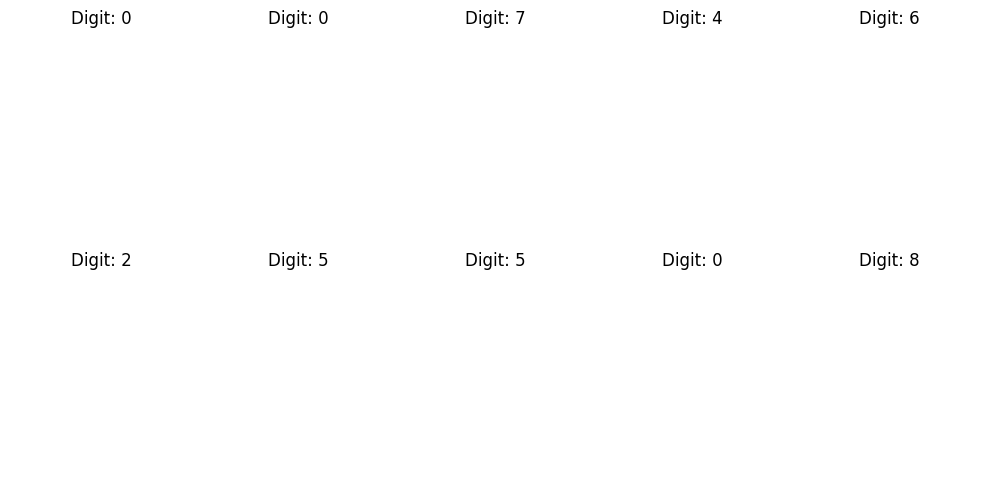

Original mean: 4.911243327402135
Scaled mean: -3.476855023737145e-18
Scaled standard deviation: 0.9842509842514757
K =  2 | Inertia =  320363.93 | Silhouette Score = 0.1090
K =  3 | Inertia =  299745.59 | Silhouette Score = 0.1019
K =  4 | Inertia =  285149.77 | Silhouette Score = 0.0882
K =  5 | Inertia =  271903.27 | Silhouette Score = 0.1111
K =  6 | Inertia =  259473.15 | Silhouette Score = 0.1025
K =  7 | Inertia =  249313.19 | Silhouette Score = 0.1177
K =  8 | Inertia =  240100.03 | Silhouette Score = 0.1265
K =  9 | Inertia =  233545.70 | Silhouette Score = 0.1346
K = 10 | Inertia =  226158.03 | Silhouette Score = 0.1383
K = 11 | Inertia =  219969.18 | Silhouette Score = 0.1415
K = 12 | Inertia =  212900.94 | Silhouette Score = 0.1463
K = 13 | Inertia =  206082.56 | Silhouette Score = 0.1515
K = 14 | Inertia =  202203.25 | Silhouette Score = 0.1455
K = 15 | Inertia =  197984.36 | Silhouette Score = 0.1435

Results:
     K        Inertia  Silhouette Score
0    2  320363.931112  

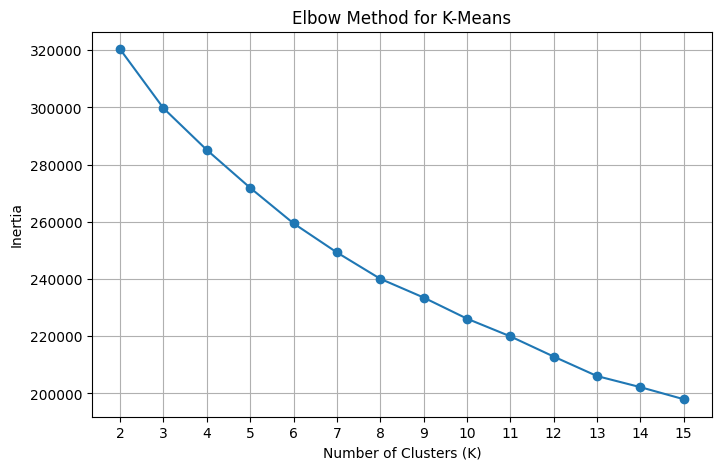

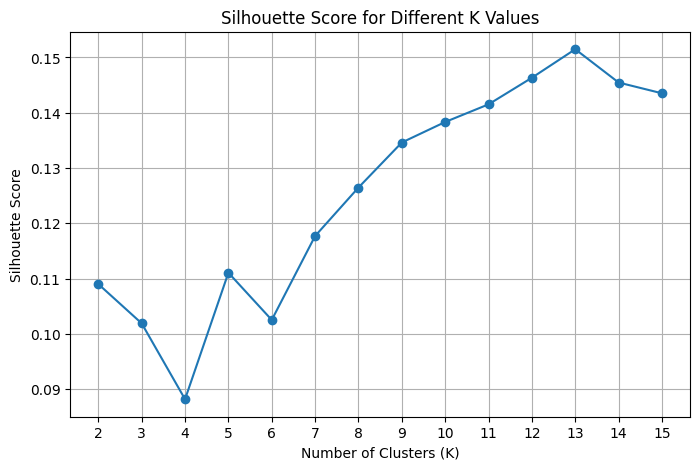


Best K based on Silhouette Score: 13
Best Silhouette Score: 0.1515

Final Model
K: 13
Inertia: 206082.5626770982
Silhouette Score: 0.15148168595710387


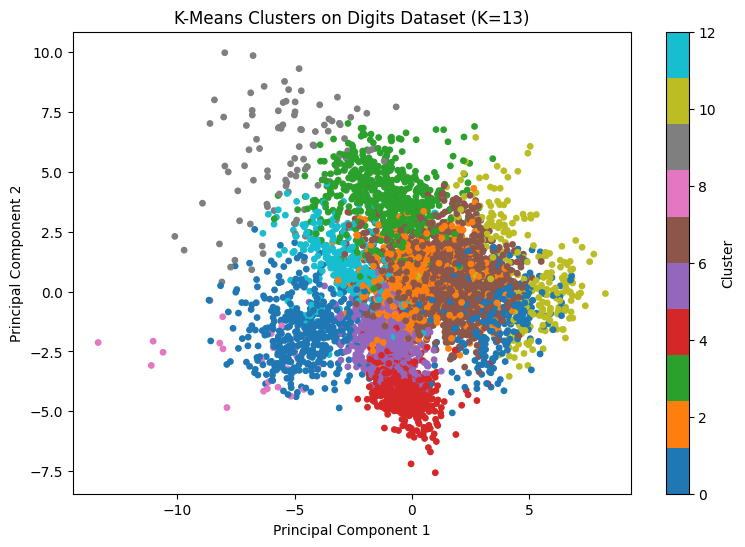


First 20 samples:
Actual labels : [0 0 7 4 6 2 5 5 0 8 7 1 9 5 3 0 4 7 8 4]
Cluster labels: [ 5  5  3 12  4  1  7  7  5  6  9 12  9  7  6  5 12  3  6 12]

Number of samples in each cluster:
0      444
1      326
2      843
3      575
4      558
5      550
6     1106
7      484
8       29
9      102
10     274
11       6
12     323
Name: count, dtype: int64


In [9]:
# ============================================================
# K-MEANS CLUSTERING ON DIGITS DATASET
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# ============================================================
# 1. LOAD DIGITS DATASET
# ============================================================

# Load training and testing datasets
train_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/optdigits/optdigits.tra"
test_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/optdigits/optdigits.tes"

train_data = np.loadtxt(train_url, delimiter=",")
test_data = np.loadtxt(test_url, delimiter=",")

# Combine both datasets
data = np.vstack((train_data, test_data))

# Separate features and target
X = data[:, :-1]
y = data[:, -1].astype(int)

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))
print("Classes:", np.unique(y))


# ============================================================
# 2. DISPLAY SOME DIGIT IMAGES
# ============================================================

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.ravel()):
    ax.set_title(f"Digit: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 3. PREPROCESSING
# ============================================================

# Standardize the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original mean:", X.mean())
print("Scaled mean:", X_scaled.mean())
print("Scaled standard deviation:", X_scaled.std())


# ============================================================
# 4. APPLY K-MEANS FOR DIFFERENT VALUES OF K
# ============================================================

k_values = range(2, 16)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    # Inertia
    inertia_values.append(kmeans.inertia_)

    # Silhouette score
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_values.append(score)

    print(
        f"K = {k:2d} | "
        f"Inertia = {kmeans.inertia_:10.2f} | "
        f"Silhouette Score = {score:.4f}"
    )


# ============================================================
# 5. CREATE RESULTS TABLE
# ============================================================

results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

print("\nResults:")
print(results)


# ============================================================
# 6. ELBOW METHOD
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()


# ============================================================
# 7. SILHOUETTE SCORE VS K
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()


# ============================================================
# 8. FIND BEST K USING SILHOUETTE SCORE
# ============================================================

best_index = np.argmax(silhouette_values)
best_k = list(k_values)[best_index]
best_score = silhouette_values[best_index]

print("\nBest K based on Silhouette Score:", best_k)
print("Best Silhouette Score:", round(best_score, 4))


# ============================================================
# 9. FINAL K-MEANS MODEL
# ============================================================

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(X_scaled)

print("\nFinal Model")
print("K:", best_k)
print("Inertia:", final_kmeans.inertia_)
print("Silhouette Score:",
      silhouette_score(X_scaled, final_labels))


# ============================================================
# 10. VISUALIZE CLUSTERS USING PCA
# ============================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=final_labels,
    cmap="tab10",
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"K-Means Clusters on Digits Dataset (K={best_k})")

plt.colorbar(scatter, label="Cluster")

plt.show()


# ============================================================
# 11. COMPARE ACTUAL DIGITS WITH CLUSTERS
# ============================================================

print("\nFirst 20 samples:")
print("Actual labels :", y[:20])
print("Cluster labels:", final_labels[:20])


# ============================================================
# 12. CLUSTER SIZE
# ============================================================

cluster_counts = pd.Series(final_labels).value_counts().sort_index()

print("\nNumber of samples in each cluster:")
print(cluster_counts)

In [ ]:
# K-MEANS CLUSTERING USING ONLINE DIGITS DATASET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 1. LOAD ONLINE DATASET

digits = fetch_ucirepo(id=80)

X = digits.data.features
y = digits.data.targets

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", y.nunique().iloc[0])

# 2. PREPROCESSING

# Convert features into numerical format
X = X.astype(float)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nPreprocessing completed!")
print("Scaled data shape:", X_scaled.shape)

# 3. APPLY K-MEANS FOR DIFFERENT K VALUES

k_values = range(2, 16)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    # Calculate inertia
    inertia_values.append(kmeans.inertia_)

    # Calculate silhouette score using a sample
    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_values.append(score)

    print("K:", k)
    print("Inertia:", round(kmeans.inertia_, 2))
    print("Silhouette Score:", round(score, 4))
    print("---------------------------")

# 4. DISPLAY RESULTS IN A TABLE

results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

print("\nCLUSTERING RESULTS")
print(results.to_string(index=False))

# 5. ELBOW METHOD

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

# 6. SILHOUETTE SCORE GRAPH

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")
plt.grid(True)
plt.show()

# 7. FIND BEST K

best_index = np.argmax(silhouette_values)

best_k = list(k_values)[best_index]

print("\nBest K:", best_k)
print("Best Silhouette Score:",
      round(silhouette_values[best_index], 4))

# 8. FINAL K-MEANS MODEL

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

final_labels = final_model.fit_predict(X_scaled)

print("\nFINAL MODEL RESULTS")
print("Number of clusters:", best_k)
print("Inertia:", round(final_model.inertia_, 2))

# 9. VISUALIZE USING PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=final_labels,
    cmap='tab10',
    s=10
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Digits Dataset")

plt.colorbar(label="Cluster")
plt.show()

# 10. DISPLAY CLUSTER DISTRIBUTION

print("\nCLUSTER DISTRIBUTION")

print(pd.Series(final_labels).value_counts().sort_index())

# 11. COMPARE ACTUAL DIGITS AND CLUSTERS

comparison = pd.DataFrame({
    "Actual Digit": y.iloc[:, 0].values,
    "Cluster": final_labels
})

print("\nACTUAL DIGIT AND CLUSTER COMPARISON")
print(comparison.head(20))

# **BAGGING AND BOOTSTRAPPING**

First five rows:
   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa

Dataset shape: (150, 5)

Class distribution:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Features shape: (150, 4)
Target shape: (150,)

========== PERFORMANCE COMPARISON ==========
                 Method  Mean Accuracy  Accuracy Std  Mean F1 Score  F1 Std
          Bootstrapping         0.9428        0.0292         0.9421  0.0293
5-Fold Cross Validation         0.9533        0.0267         0.9530  0.0257

Bootstrap iterations: 100
Cross-validation folds: 5


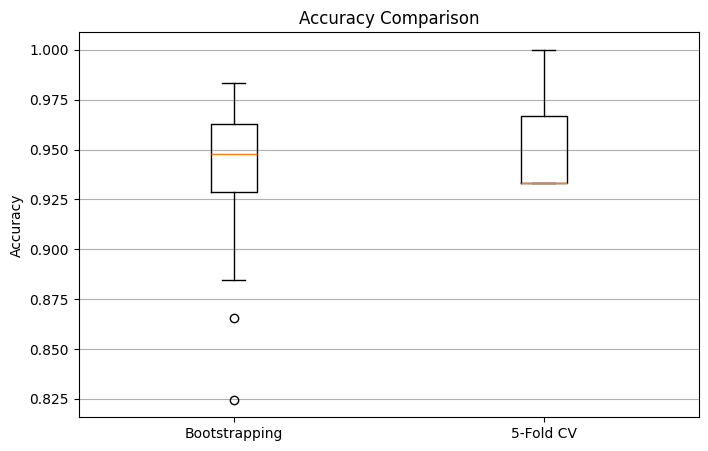

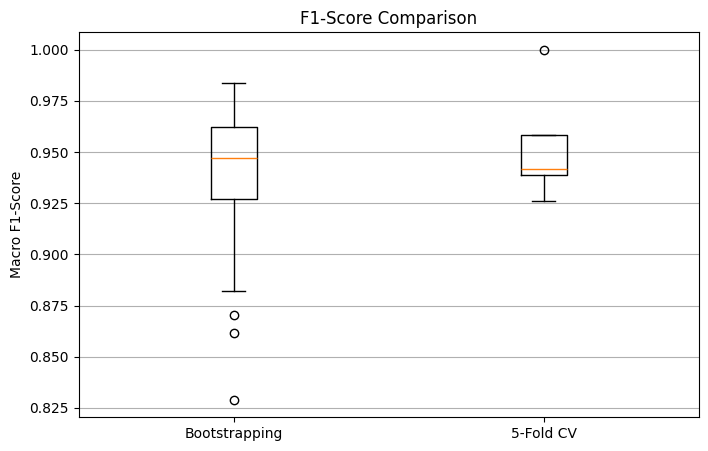

In [10]:

# Bootstrapping and K-Fold Cross-Validation on Online Iris Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------
# 1. LOAD ONLINE IRIS DATASET
# ------------------------------------------------

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

df = pd.read_csv(url, names=columns)

# Remove empty rows, if any
df.dropna(inplace=True)

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df["species"].value_counts())

# ------------------------------------------------
# 2. PREPROCESS THE DATA
# ------------------------------------------------

X = df.drop("species", axis=1).values
y = df["species"].values

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

# ------------------------------------------------
# 3. BOOTSTRAPPING
# ------------------------------------------------

np.random.seed(42)

n_samples = len(X)
n_bootstraps = 100

bootstrap_accuracy = []
bootstrap_f1 = []

for i in range(n_bootstraps):

    # Random sampling with replacement
    indices = np.random.choice(
        n_samples,
        size=n_samples,
        replace=True
    )

    # Training data
    X_train = X[indices]
    y_train = y[indices]

    # Find out-of-bag samples
    oob_mask = np.ones(n_samples, dtype=bool)
    oob_mask[np.unique(indices)] = False

    X_test = X[oob_mask]
    y_test = y[oob_mask]

    if len(X_test) == 0:
        continue

    # Create and train Decision Tree
    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Evaluation
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")

    bootstrap_accuracy.append(acc)
    bootstrap_f1.append(f1)

# ------------------------------------------------
# 4. K-FOLD CROSS-VALIDATION
# ------------------------------------------------

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_accuracy = []
cv_f1 = []

for train_index, test_index in kf.split(X):

    # Split training and testing data
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Create and train model
    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Evaluation
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")

    cv_accuracy.append(acc)
    cv_f1.append(f1)

# ------------------------------------------------
# 5. COMPARE PERFORMANCE
# ------------------------------------------------

results = pd.DataFrame({
    "Method": [
        "Bootstrapping",
        "5-Fold Cross Validation"
    ],

    "Mean Accuracy": [
        np.mean(bootstrap_accuracy),
        np.mean(cv_accuracy)
    ],

    "Accuracy Std": [
        np.std(bootstrap_accuracy),
        np.std(cv_accuracy)
    ],

    "Mean F1 Score": [
        np.mean(bootstrap_f1),
        np.mean(cv_f1)
    ],

    "F1 Std": [
        np.std(bootstrap_f1),
        np.std(cv_f1)
    ]
})

print("\n========== PERFORMANCE COMPARISON ==========")
print(results.round(4).to_string(index=False))

print("\nBootstrap iterations:", len(bootstrap_accuracy))
print("Cross-validation folds:", len(cv_accuracy))

# ------------------------------------------------
# 6. VISUALIZE ACCURACY
# ------------------------------------------------

plt.figure(figsize=(8, 5))

plt.boxplot(
    [bootstrap_accuracy, cv_accuracy],
    tick_labels=["Bootstrapping", "5-Fold CV"]
)

plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")
plt.grid(axis="y")
plt.show()

# ------------------------------------------------
# 7. VISUALIZE F1 SCORE
# ------------------------------------------------

plt.figure(figsize=(8, 5))

plt.boxplot(
    [bootstrap_f1, cv_f1],
    tick_labels=["Bootstrapping", "5-Fold CV"]
)

plt.title("F1-Score Comparison")
plt.ylabel("Macro F1-Score")
plt.grid(axis="y")
plt.show()


# **ENSAMPLING AND CROSS VALIDATION**

Dataset loaded successfully!
Dataset shape: (891, 15)
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

Missing values:
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64

Training data: (712, 7

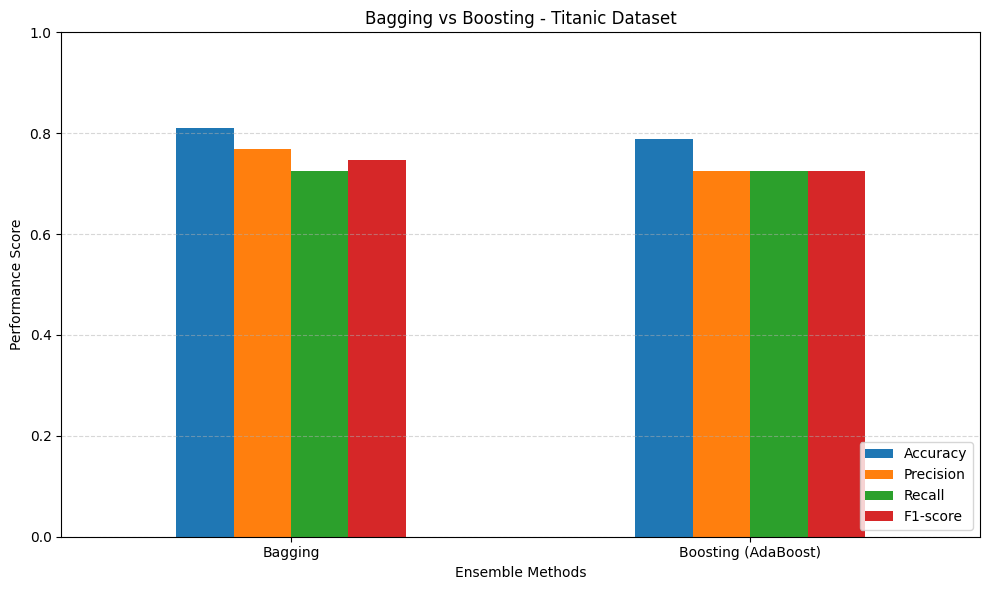


========== FINAL RESULT ==========
Best model based on F1-score: Bagging

Experiment completed successfully!


In [11]:

# BAGGING AND BOOSTING USING ONLINE TITANIC DATASET

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. LOAD ONLINE TITANIC DATASET

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

# 2. SELECT FEATURES AND TARGET

features = [
    "pclass", "sex", "age", "sibsp",
    "parch", "fare", "embarked"
]

X = df[features]
y = df["survived"]

print("\nMissing values:")
print(X.isnull().sum())

# 3. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES

numeric_features = [
    "pclass", "age", "sibsp", "parch", "fare"
]

categorical_features = [
    "sex", "embarked"
]

# 4. PREPROCESSING

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# 5. SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)

# 6. BAGGING MODEL

bagging_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        max_samples=1.0,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ))
])

bagging_model.fit(X_train, y_train)

bagging_predictions = bagging_model.predict(X_test)

# 7. BOOSTING MODEL - ADABOOST

boosting_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            random_state=42
        ),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ))
])

boosting_model.fit(X_train, y_train)

boosting_predictions = boosting_model.predict(X_test)

# 8. EVALUATION FUNCTION

def evaluate_model(y_actual, y_predicted):

    accuracy = accuracy_score(y_actual, y_predicted)

    precision = precision_score(
        y_actual, y_predicted, zero_division=0
    )

    recall = recall_score(
        y_actual, y_predicted, zero_division=0
    )

    f1 = f1_score(
        y_actual, y_predicted, zero_division=0
    )

    return [accuracy, precision, recall, f1]


# 9. CALCULATE PERFORMANCE METRICS

bagging_results = evaluate_model(
    y_test, bagging_predictions
)

boosting_results = evaluate_model(
    y_test, boosting_predictions
)

# 10. COMPARISON TABLE

results = pd.DataFrame(
    [bagging_results, boosting_results],
    columns=["Accuracy", "Precision", "Recall", "F1-score"],
    index=["Bagging", "Boosting (AdaBoost)"]
)

print("\n========== PERFORMANCE COMPARISON ==========")
print(results.round(4))

# 11. CLASSIFICATION REPORT

print("\n========== BAGGING REPORT ==========")

print(classification_report(
    y_test,
    bagging_predictions,
    target_names=["Not Survived", "Survived"],
    zero_division=0
))

print("\n========== BOOSTING REPORT ==========")

print(classification_report(
    y_test,
    boosting_predictions,
    target_names=["Not Survived", "Survived"],
    zero_division=0
))

# 12. PERFORMANCE GRAPH

results.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Bagging vs Boosting - Titanic Dataset")
plt.xlabel("Ensemble Methods")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 13. FIND THE BEST MODEL

print("\n========== FINAL RESULT ==========")

best_model = results["F1-score"].idxmax()

print("Best model based on F1-score:", best_model)

print("\nExperiment completed successfully!")


# **nexttttttttttttttt**